### Executable study D — assistant-authored obligation and revision diagnostics

A native Langflow research assistant wrote the implementation and experiment. A separate coordinator wrote the fixtures, withheld acceptance manifest and checker. This is internal collaboration, not external peer review. Original disagreements and code are preserved. The cells below independently recount and reproduce saved evidence; no task workflow is run.

In [1]:
from pathlib import Path
import json, sys, collections
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'knowledge/research/paper-6-study').exists())
study = ROOT / 'knowledge/research/paper-6-study'
art = study / 'assistant-workspace/artifacts'
sys.path.insert(0, str(study))
from verify_assistant_experiment import verify
results = json.loads((art / 'obligation-results.json').read_text())
assessment = verify(art / 'obligation-results.json')
base = [r for r in results['records'] if r['variant'] == 'base']
assert len(base) == 24 and len(results['records']) == 96
print('Preserved first run:', assessment['resultSha256'])
print('Independent checker assertions:', assessment['checks'])
print('Unresolved original acceptance differences:', len(assessment['failures']))
print('24 base cases + 72 transformations; not 96 independent observations.')


Preserved first run: 1960ab762f9912b67def5bfd50b2956e25d1f4a69bff6a416986e2fbfdcdbb9d
Independent checker assertions: 927
Unresolved original acceptance differences: 4
24 base cases + 72 transformations; not 96 independent observations.


In [2]:
rows = ['| Case | Ports only | Required fields | Ledger action | Blockers |', '|---|---|---|---|---|']
for r in base:
    d = r['decisions']
    rows.append('| ' + ' | '.join([r['base_case_id'], d['B0']['action'], d['B1']['action'], d['ledger']['action'], ', '.join(b['kind'] for b in d['ledger']['blockers']) or 'None at static tier']) + ' |')
display(Markdown('\n'.join(rows)))
print('Original action agreement: 23/24 base cases; C17 disagrees on ASK versus REJECT_SCOPE.')
print('All mandatory blocker, checked witness, authorized patch and action/blocker metamorphic assertions pass.')
print('These are internal authored conformance cases, not efficacy or generalization evidence.')


| Case | Ports only | Required fields | Ledger action | Blockers |
|---|---|---|---|---|
| C01 | PORTS_PASS | FIELDS_FAIL | ASK | required_model |
| C02 | PORTS_PASS | FIELDS_PASS | SPEC_GROUNDED | None at static tier |
| C03 | PORTS_PASS | FIELDS_PASS | ASK | required_model |
| C04 | PORTS_PASS | FIELDS_FAIL | ASK | required_input |
| C05 | PORTS_PASS | FIELDS_PASS | SPEC_GROUNDED | None at static tier |
| C06 | PORTS_FAIL | FIELDS_FAIL | ASK | edge_type_conflict |
| C07 | PORTS_PASS | FIELDS_PASS | REJECT_SCOPE | unsupported_capability |
| C08 | PORTS_PASS | FIELDS_PASS | REJECT_SCOPE | unsupported_capability |
| C09 | PORTS_PASS | FIELDS_PASS | REJECT_SCOPE | unsupported_capability |
| C10 | PORTS_FAIL | FIELDS_FAIL | ASK | node_type_conflict |
| C11 | PORTS_PASS | FIELDS_FAIL | ASK | model_conflict |
| C12 | PORTS_PASS | FIELDS_PASS | ASK | intent_conflict |
| C13 | PORTS_PASS | FIELDS_FAIL | ASK | orphan_binding, required_model |
| C14 | PORTS_PASS | FIELDS_PASS | REVISE | None at static tier |
| C15 | PORTS_PASS | FIELDS_PASS | ASK | ambiguous_identity |
| C16 | PORTS_PASS | FIELDS_PASS | SPEC_GROUNDED | None at static tier |
| C17 | PORTS_PASS | FIELDS_PASS | ASK | runtime_certification |
| C18 | PORTS_PASS | FIELDS_PASS | ASK | provider_requirements_unknown |
| C19 | PORTS_PASS | FIELDS_PASS | ASK | intent_route |
| C20 | PORTS_PASS | FIELDS_PASS | REVISE | None at static tier |
| C21 | PORTS_PASS | FIELDS_PASS | ASK | revision_intent_conflict |
| C22 | PORTS_PASS | FIELDS_PASS | SPEC_GROUNDED | None at static tier |
| C23 | PORTS_PASS | FIELDS_FAIL | REJECT_SCOPE | unsupported_capability, required_model |
| C24 | PORTS_PASS | FIELDS_FAIL | ASK | orphan_binding, required_model |

Original action agreement: 23/24 base cases; C17 disagrees on ASK versus REJECT_SCOPE.
All mandatory blocker, checked witness, authorized patch and action/blocker metamorphic assertions pass.
These are internal authored conformance cases, not efficacy or generalization evidence.


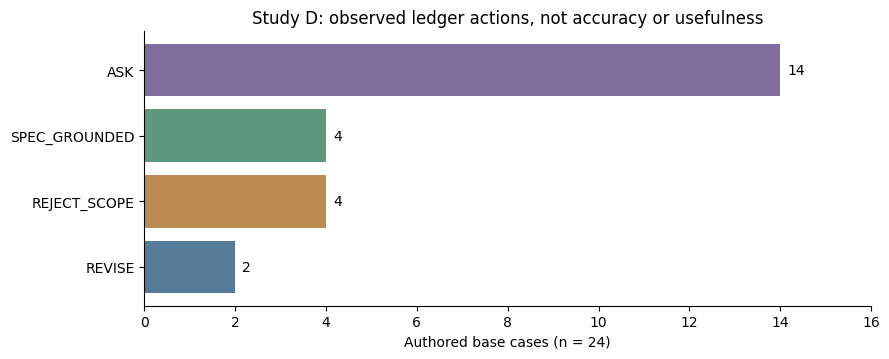

In [3]:
import matplotlib.pyplot as plt
counts = collections.Counter(r['decisions']['ledger']['action'] for r in base)
labels = ['ASK','SPEC_GROUNDED','REJECT_SCOPE','REVISE']
fig, ax = plt.subplots(figsize=(9, 3.7))
values = [counts[x] for x in labels]
bars = ax.barh(labels[::-1], values[::-1], color=['#557b99','#bd8c53','#5d997f','#806d9e'])
for bar in bars: ax.text(bar.get_width()+.15, bar.get_y()+bar.get_height()/2, str(int(bar.get_width())), va='center')
ax.set(xlabel='Authored base cases (n = 24)', xlim=(0,16), title='Study D: observed ledger actions, not accuracy or usefulness')
ax.spines[['top','right']].set_visible(False)
fig.tight_layout(); plt.show()


In [4]:
# Reproduce every saved base decision from the frozen agent-authored implementation.
import importlib.util, hashlib
spec = importlib.util.spec_from_file_location('paper6_obligation_reproduction', art / 'obligation_ledger.py')
module = importlib.util.module_from_spec(spec); spec.loader.exec_module(module)
catalog = json.loads((study / 'native-starter-catalog.json').read_text())
for name, expected in results['source_hashes'].items():
    path = study / 'assistant-workspace' / name
    assert hashlib.sha256(path.read_bytes()).hexdigest() == expected, name
for record in base:
    for method in ['B0','B1','ledger']:
        assert module.evaluate(record['input'],catalog,method) == record['decisions'][method]
print('Reproduced 72/72 base-case method decisions exactly from pinned code and inputs.')
print('No workflow, provider, Langflow component, or language model was executed in this reproduction.')
for cid in ['C03','C14','C20','C21']:
    r = next(r for r in base if r['base_case_id']==cid)
    d = r['decisions']['ledger']
    print(cid, d['action'], 'patches:', [p['op'] for p in d['patches']], 'blockers:', [b['kind'] for b in d['blockers']])


Reproduced 72/72 base-case method decisions exactly from pinned code and inputs.
No workflow, provider, Langflow component, or language model was executed in this reproduction.
C03 ASK patches: ['revoke_model'] blockers: ['required_model']
C14 REVISE patches: ['rename_node'] blockers: []
C20 REVISE patches: ['route_through_agent'] blockers: []
C21 ASK patches: [] blockers: ['revision_intent_conflict']
